# JagaDia - 01. Exploratory Data Analysis & Baseline Model

Notebook ini bertujuan untuk:
1. Memuat dataset kriminalitas dan data lingkungan (*spatial & temporal*).
2. Melakukan analisis distribusi spasial (hotspot) dan temporal (jam rawan).
3. Membangun model baseline (Random Forest & XGBoost) untuk klasifikasi risiko kerawanan jalan.

In [110]:
import sys
from pathlib import Path

# Tambahkan direktori root ML ke path
ml_root = Path.cwd().parent
if str(ml_root) not in sys.path:
    sys.path.append(str(ml_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_DATA_DIR, PROCESSED_DATA_DIR, RANDOM_STATE
from src.data_pipeline import generate_mock_crime_dataset, load_data
from src.features import extract_temporal_features

print("Setup completed successfully.")

Setup completed successfully.


## 1. Load Data
Jika data riil belum tersedia, kita dapat men-generate data uji realistis menggunakan modul `data_pipeline`.

In [111]:
raw_csv = RAW_DATA_DIR / "data-rawan-ketertiban-umum-komponen-data 2024.csv"
if not raw_csv.exists():
    df = generate_mock_crime_dataset(n_samples=2000, output_path=raw_csv)
else:
    df = load_data(raw_csv)

df.head()

,periode_data,wilayah,kecamatan,kelurahan,latitude,longitude,jenis_rawan
0,2024,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6170529.000000,106819195,PENGEMIS
1,2024,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6170492.000000,106819266,PKL
2,2024,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6160866.000000,106802437,TAWURAN (WARGA / PELAJAR)
3,2024,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6159615.000000,106804436,TAWURAN (WARGA / PELAJAR)
4,2024,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI UTARA,-6155287.000000,106801734,PKL


## 2. Univariate Analysis

In [112]:
df.shape

(1018, 7)

df memiliki 1018 rows dan 7 columns

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   periode_data  1018 non-null   int64  
 1   wilayah       1018 non-null   object 
 2   kecamatan     1018 non-null   object 
 3   kelurahan     1018 non-null   object 
 4   latitude      1018 non-null   float64
 5   longitude     1018 non-null   int64  
 6   jenis_rawan   1018 non-null   object 
dtypes: float64(1), int64(2), object(4)
memory usage: 55.8+ KB


In [114]:
df.describe(include="object")

,wilayah,kecamatan,kelurahan,jenis_rawan
count,1018,1018,1018,1018
unique,6,44,253,14
top,KOTA ADM. JAKARTA TIMUR,CIPAYUNG,PEGADUNGAN,PKL
freq,286,61,36,340


In [115]:
pd.options.display.float_format = "{:.6f}".format
df[["latitude", "longitude"]].describe()

,latitude,longitude
count,1018.000000,1018.000000
mean,-91304656.479875,208545661.105108
std,697761100.008951,296428090.622838
min,-6291907787.000000,1068738.000000
25%,-6284498.750000,106808760.000000
50%,-6203867.000000,106848388.500000
75%,-6160010.750000,106895448.500000
max,6173759.000000,1069560018.000000


In [116]:
df["latitude"].astype(str).str.len().value_counts()
df["longitude"].astype(str).str.len().value_counts()


longitude
9     907
10    108
7       2
8       1
Name: count, dtype: int64

In [117]:
df.isnull().sum()

periode_data    0
wilayah         0
kecamatan       0
kelurahan       0
latitude        0
longitude       0
jenis_rawan     0
dtype: int64

In [118]:
df.duplicated().sum()

np.int64(0)

Memperbaiki struktur tulisan longitude dan latitude

In [119]:
def fix_coord(v, n_lead):
    if abs(v) < 10**n_lead:      # sudah desimal, jangan diubah
        return v
    s = str(int(abs(v)))
    return np.sign(v) * float(s[:n_lead] + "." + s[n_lead:])

df["lat"] = df["latitude"].apply(lambda v: fix_coord(v, 1))
df["lon"] = df["longitude"].apply(lambda v: fix_coord(v, 3))

df[["lat", "lon"]].describe()

,lat,lon
count,1018.000000,1018.000000
mean,-6.178783,106.833303
std,0.553101,0.070360
min,-6.366978,106.081053
25%,-6.250259,106.804307
50%,-6.197408,106.841930
75%,-6.158112,106.879382
max,6.173759,106.972953


Melihat data outlier dari latitude dan longitude

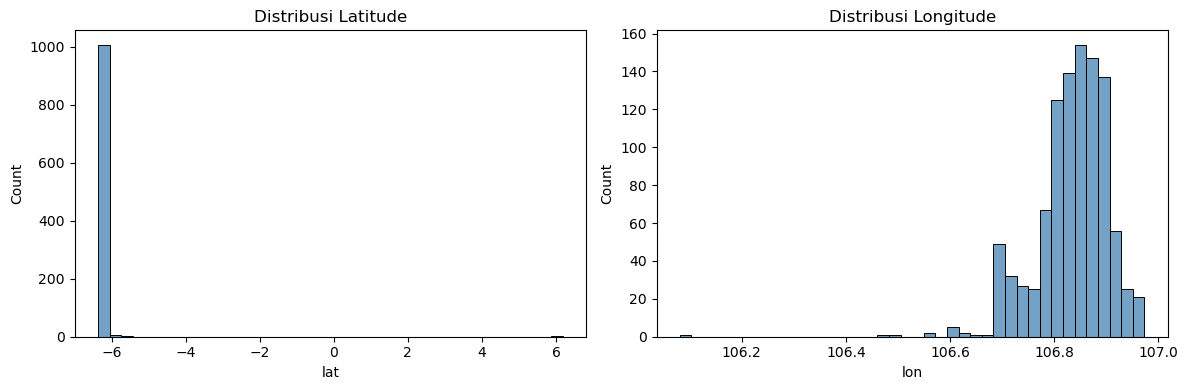

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["lat"], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Latitude")

sns.histplot(df["lon"], bins=40, ax=axes[1], color="steelblue")
axes[1].set_title("Distribusi Longitude")

plt.tight_layout()
plt.show()

Melihat data outlier dari kelurahan

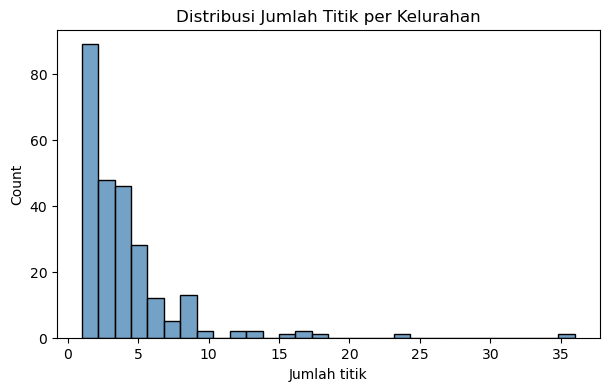

In [121]:
per_kel = df["kelurahan"].value_counts()

plt.figure(figsize=(7, 4))
sns.histplot(per_kel, bins=30, color="steelblue")
plt.title("Distribusi Jumlah Titik per Kelurahan")
plt.xlabel("Jumlah titik")
plt.show()

Melihat banyaknya jenis rawan di setiap wilayah

In [122]:
df["jenis_rawan"].value_counts()
df["wilayah"].value_counts()
df["kecamatan"].value_counts().head(10)
df["kelurahan"].value_counts().head(10)
pd.crosstab(df["wilayah"], df["jenis_rawan"])

jenis_rawan,KRIMINALITAS,ORMAS / WARGA,PAK OGAH,PARKIR LIAR,PEDAGANG ASONGAN,PELANGGARAN PERIJINAN,PENGAMEN,PENGAMEN (COSTPLAY),PENGAMEN (MANUSIA SILVER),PENGEMIS,PENYALAHGUNAAN (FASUM/FASOS),PKL,PSK,TAWURAN (WARGA / PELAJAR)
wilayah,,,,,,,,,,,,,,
KAB. ADM. KEP. SERIBU,0,0,0,0,0,0,0,0,0,0,0,9,0,0
KOTA ADM. JAKARTA BARAT,3,2,30,15,1,1,0,0,2,4,13,91,1,7
KOTA ADM. JAKARTA PUSAT,13,7,22,19,4,2,6,3,1,13,34,63,3,22
KOTA ADM. JAKARTA SELATAN,4,4,12,27,8,7,9,6,4,13,38,71,0,9
KOTA ADM. JAKARTA TIMUR,13,4,24,45,11,2,14,0,4,14,65,66,2,22
KOTA ADM. JAKARTA UTARA,11,4,19,18,1,0,1,0,4,3,15,40,1,12


### 2.1 Distribusi jenis rawan

Melihat jenis rawan terbanyak

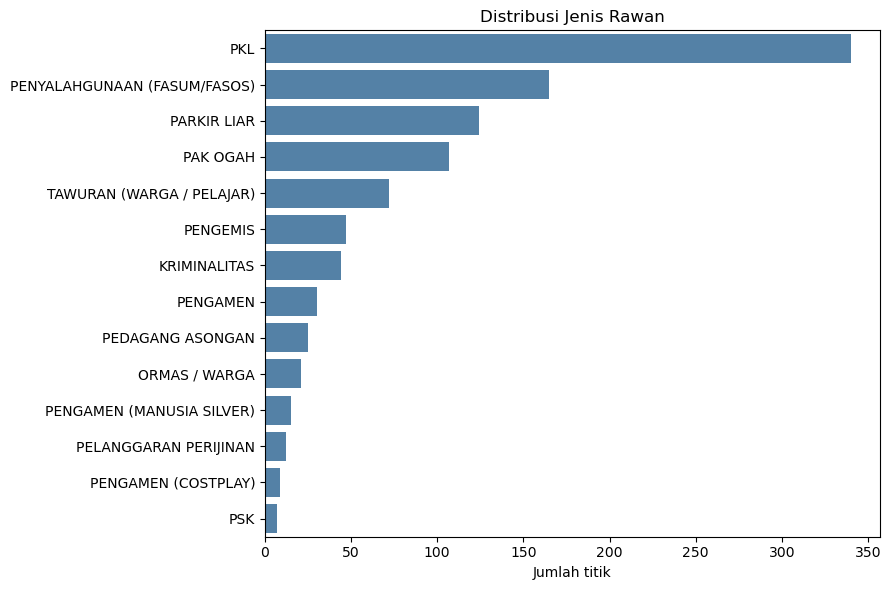

In [123]:
plt.figure(figsize=(9, 6))
order = df["jenis_rawan"].value_counts().index
sns.countplot(data=df, y="jenis_rawan", order=order, color="steelblue")
plt.title("Distribusi Jenis Rawan")
plt.xlabel("Jumlah titik")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 2.2 Distribusi Wilayah

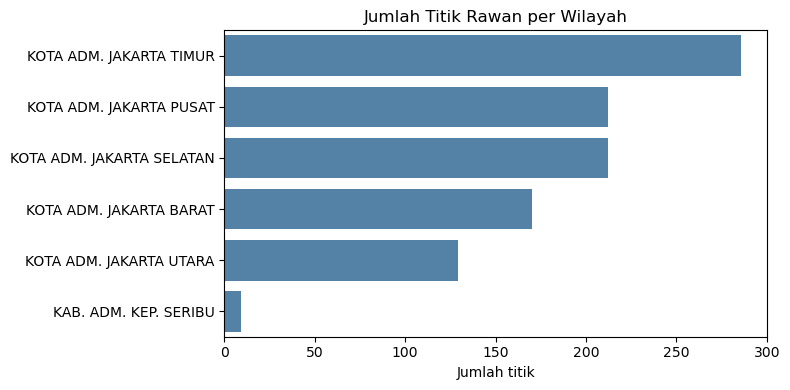

In [124]:
plt.figure(figsize=(8, 4))
order = df["wilayah"].value_counts().index
sns.countplot(data=df, y="wilayah", order=order, color="steelblue")
plt.title("Jumlah Titik Rawan per Wilayah")
plt.xlabel("Jumlah titik")
plt.ylabel("")
plt.tight_layout()
plt.show()

Dari bar chart dapat dilihat bahwa jumlah titik rawan terbanyak ada di daerah jakarta timur dan paling sedikit ada di kepulauan seribu

### 2.3 Top 10 kecamatan dan kelurahan yang rawan kejahatan

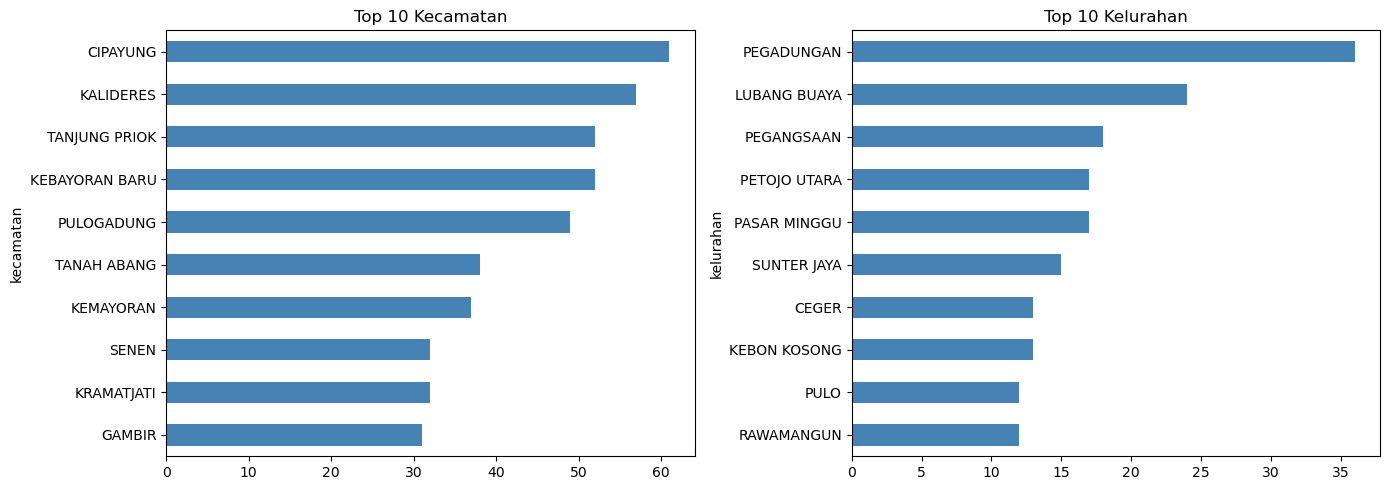

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["kecamatan"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Kecamatan")

df["kelurahan"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Top 10 Kelurahan")

plt.tight_layout()
plt.show()

## 3. Bivariate Analysis

### 3.1 Korelasi wilayah dan jenis rawan

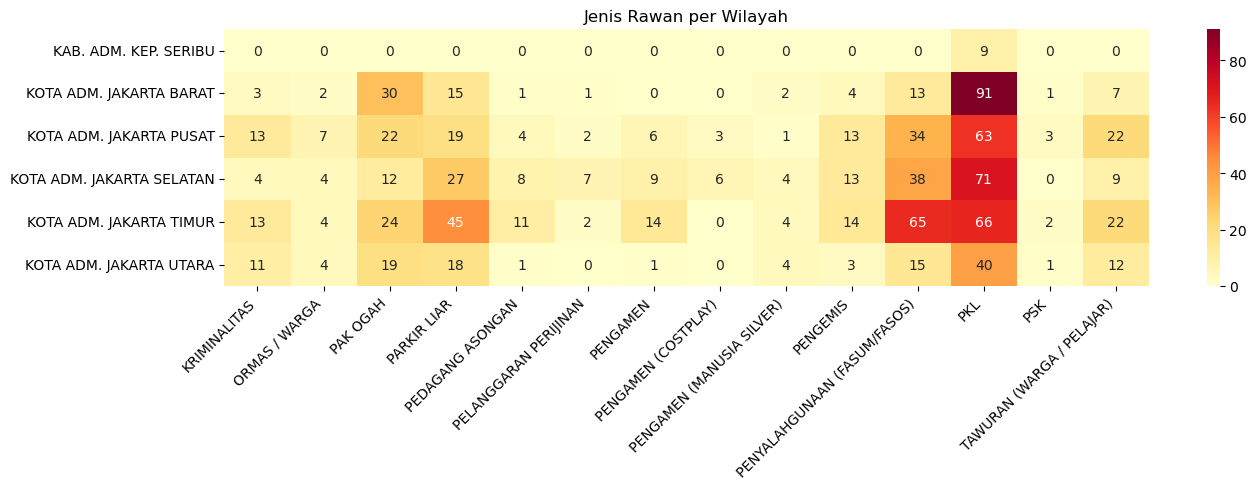

In [126]:
ct = pd.crosstab(df["wilayah"], df["jenis_rawan"])

plt.figure(figsize=(14, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Jenis Rawan per Wilayah")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

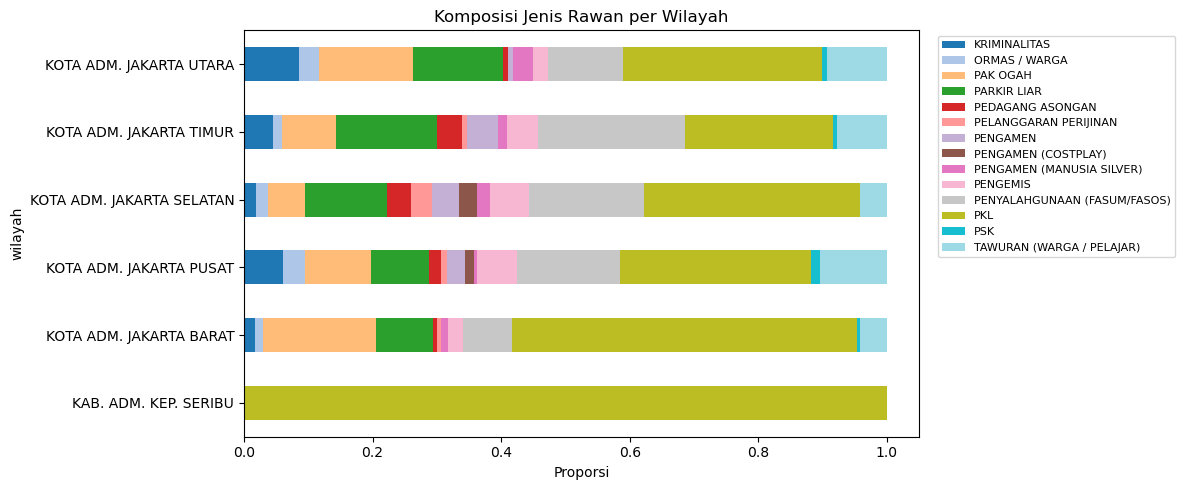

In [127]:
ct_pct = pd.crosstab(df["wilayah"], df["jenis_rawan"], normalize="index")
ct_pct.plot(kind="barh", stacked=True, figsize=(12, 5), colormap="tab20")
plt.title("Komposisi Jenis Rawan per Wilayah")
plt.xlabel("Proporsi")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Dari sini dapat dilihat bahwa jenis rawan PKL (Praktik Kerja Lapangan) mendominasi keseluruhan wilayah. Hal ini sangat wajar, karena banyak siswa SMK yang perlu melakukan PKL sebagai salah satu syarat kelulusan merak.
Selain itu, hampir seluruh wilayah juga mengalami banyak sekali parkir liar dan juga penyalahgunaan fasum

### 3.2 Korelasi Kecamatan dan Jenis rawan

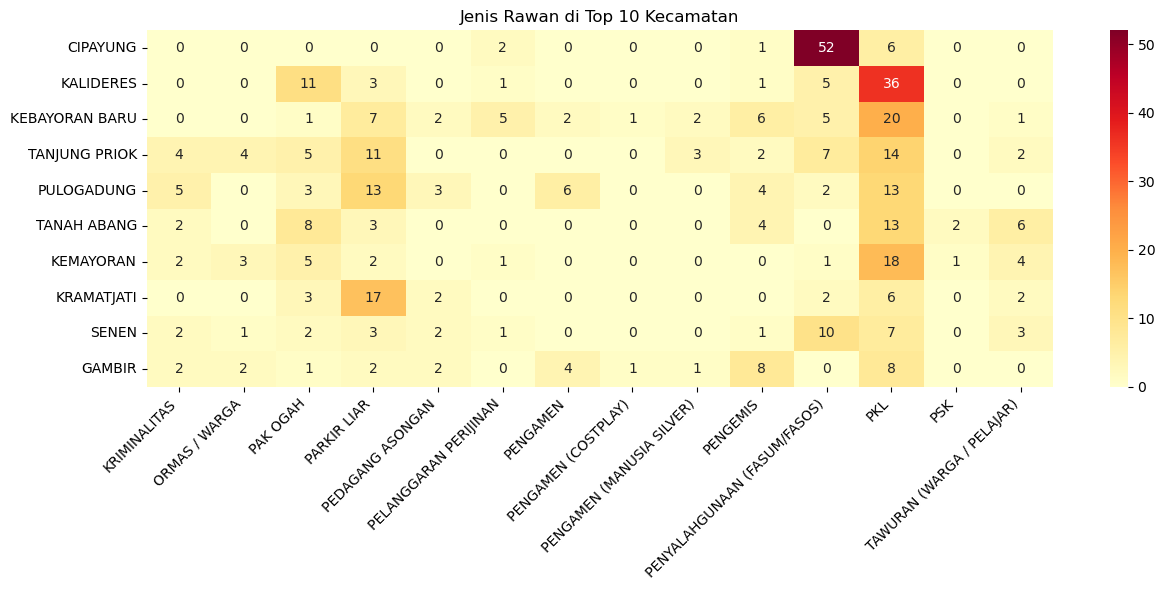

In [128]:
top_kec = df["kecamatan"].value_counts().head(10).index
d_kec = df[df["kecamatan"].isin(top_kec)]

ct_kec = pd.crosstab(d_kec["kecamatan"], d_kec["jenis_rawan"])
ct_kec = ct_kec.loc[top_kec]   # urut dari terbanyak

plt.figure(figsize=(13, 6))
sns.heatmap(ct_kec, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Jenis Rawan di Top 10 Kecamatan")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Dapat dilihat bahwa jenis rawan terbanyak adalah penyalahgunaan fasilitas umum yang marak terjadi di kecamatan cipayung. Selain itu PKL juga banyak terjadi di beberapa kecamatan seperti Kalideres, Kebayoran Baru, dan Kemayoran. Parkir liar hampir sering terjadi di beberapa kecamatan seperti Kramajati, Pulogadung, dan juga Tanjung Priok.

### 3.3 Korelasi Kelurahan dan Jenis rawan

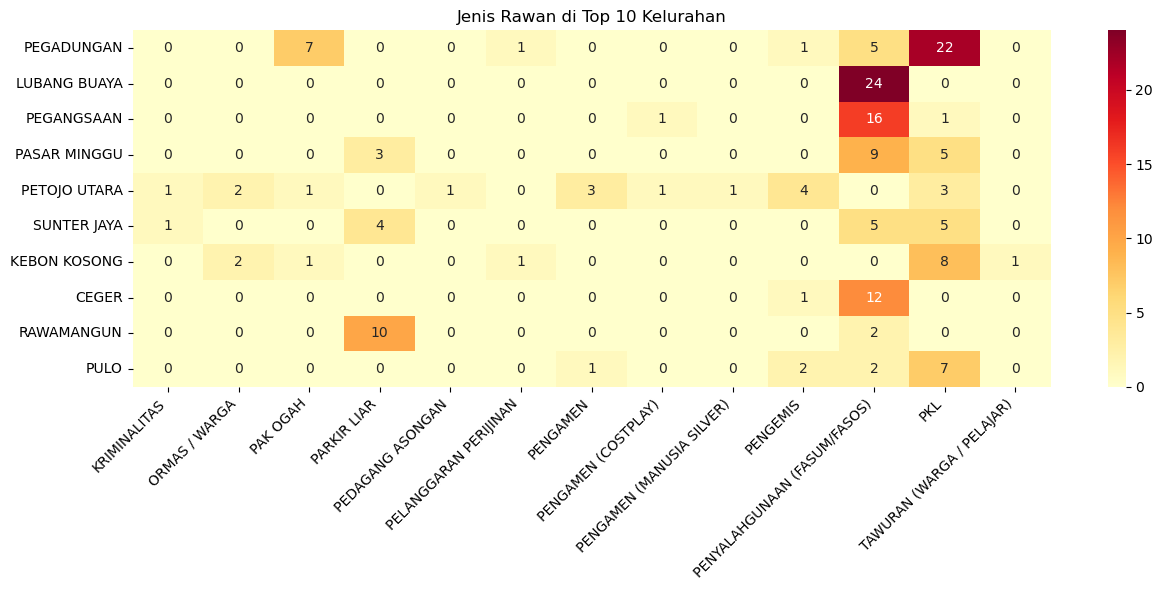

In [129]:
top_kel = df["kelurahan"].value_counts().head(10).index
d_kel = df[df["kelurahan"].isin(top_kel)]

ct_kel = pd.crosstab(d_kel["kelurahan"], d_kel["jenis_rawan"])
ct_kel = ct_kel.loc[top_kel]

plt.figure(figsize=(13, 6))
sns.heatmap(ct_kel, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Jenis Rawan di Top 10 Kelurahan")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.4 Perhitungan Cramer V

Menghitung ukuran kekuatan hubungan antara dua kolom kategorikal (nilai 0 sampai 1). Dipakai karena korelasi biasa (Pearson) hanya bisa untuk angka, sedangkan kolom berupa teks kategori.

In [130]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    # koreksi bias
    phi2 = max(0, chi2/n - (k-1)*(r-1)/(n-1))
    r_c = r - (r-1)**2/(n-1)
    k_c = k - (k-1)**2/(n-1)
    return np.sqrt(phi2 / min(k_c-1, r_c-1))

print("kecamatan vs jenis_rawan :", round(cramers_v(df["kecamatan"], df["jenis_rawan"]), 3))
print("kelurahan vs jenis_rawan :", round(cramers_v(df["kelurahan"], df["jenis_rawan"]), 3))
print("wilayah   vs jenis_rawan :", round(cramers_v(df["wilayah"], df["jenis_rawan"]), 3))

kecamatan vs jenis_rawan : 0.219
kelurahan vs jenis_rawan : 0.259
wilayah   vs jenis_rawan : 0.146


Dari perhitungan menggunakan cramer V, dapat dilihat hubungan paling dekat dengan jenis rawan, dimana 0 berarti tidak berhubungan dan 1 berarti sangat berhubungan.
Dari hasil, didapat:
1. Korelasi kecamatan dan jenis rawan lemah ke sedang
2. Korelasi kelurahan dan jenis rawan sedang
3. Korelasi wilayah dan jenis rawan lemah

## 4. Spasial Analysis

### 4.1 Persiapan Data Spasial

Kolom `latitude` dan `longitude` pada data mentah tersimpan sebagai bilangan bulat tanpa tanda desimal (misalnya `-6170529` dan `106819195`) dengan skala yang tidak konsisten. Sebagian kecil baris (20 data) sudah berupa desimal. Selain itu ditemukan beberapa anomali koordinat. Karena itu, sebelum analisis spasial dilakukan, koordinat dikoreksi dengan langkah berikut:

1. Menyisipkan tanda desimal (setelah 1 digit untuk latitude, setelah 3 digit untuk longitude), tanpa mengubah nilai yang sudah berupa desimal.
2. Memperbaiki 2 baris latitude yang bernilai positif (salah tanda).
3. Memisahkan 9 titik Kepulauan Seribu karena koordinatnya valid tetapi terpisah dari daratan.
4. Membuang 2 baris dengan longitude di luar rentang daratan Jakarta (salah ketik).

In [131]:
df_baru = df.copy()

df_baru["lat"] = df_baru["latitude"].apply(lambda v: fix_coord(v, 1))
df_baru["lon"] = df_baru["longitude"].apply(lambda v: fix_coord(v, 3))

print("Latitude positif:", (df_baru["lat"] > 0).sum())
df_baru.loc[df_baru["lat"] > 0, "lat"] *= -1

seribu = df_baru[df_baru["wilayah"].str.contains("SERIBU")]
df_baru = df_baru[~df_baru["wilayah"].str.contains("SERIBU")]
print("Kepulauan Seribu dipisah:", len(seribu))

n_sebelum = len(df_baru)
df_baru = df_baru[df_baru["lat"].between(-6.5, -5.9) & df_baru["lon"].between(106.6, 107.1)].copy()
print("Dibuang (salah ketik):", n_sebelum - len(df_baru))

print("Sisa data:", len(df_baru))

Latitude positif: 2
Kepulauan Seribu dipisah: 9
Dibuang (salah ketik): 2
Sisa data: 1007


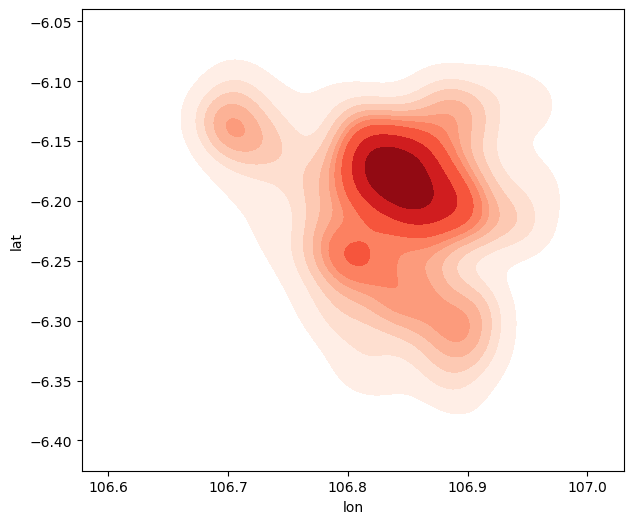

In [132]:
plt.figure(figsize=(7, 7))
sns.kdeplot(data=df_baru, x="lon", y="lat", fill=True, cmap="Reds", thresh=0.05)
plt.gca().set_aspect("equal")
plt.show()

Dari hasil KDE 2D, terlihat bahwa sebaran titik rawan ketertiban umum di DKI Jakarta tidak merata dan membentuk beberapa area dengan kepadatan berbeda. Kepadatan tertinggi (warna merah gelap) berada di sekitar lat -6.18 dan lon 106.84, yang berkaitan dengan wilayah Jakarta Pusat. Selain itu, terdapat beberapa kantong kepadatan yang lebih kecil: di bagian barat (sekitar lat -6.14, lon 106.70) yang berkaitan dengan area Kalideres/Pegadungan, di bagian selatan (sekitar lat -6.245, lon 106.81) pada area Jakarta Selatan, serta area memanjang ke arah tenggara (sekitar lat -6.30, lon 106.89) yang berkaitan dengan area Cipayung. Area di luar kantong-kantong tersebut, terutama bagian utara dan timur laut, memiliki kepadatan yang jauh lebih rendah.

Perlu diperhatikan bahwa KDE menggambarkan kepadatan titik yang tercatat dalam data, bukan tingkat bahaya atau frekuensi kejadian sebenarnya, sehingga area dengan kepadatan tinggi dapat dipengaruhi oleh intensitas pendataan. Selain itu, visualisasi ini masih mencakup seluruh jenis rawan, termasuk PKL yang mendominasi sekitar sepertiga data.

Pola ini menunjukkan bahwa data memiliki struktur spasial yang cukup jelas, sehingga layak dilanjutkan ke analisis clustering untuk mengidentifikasi zona rawan secara lebih objektif.

### 4.2 Sebaran Titik Rawan (Scatter Plot)

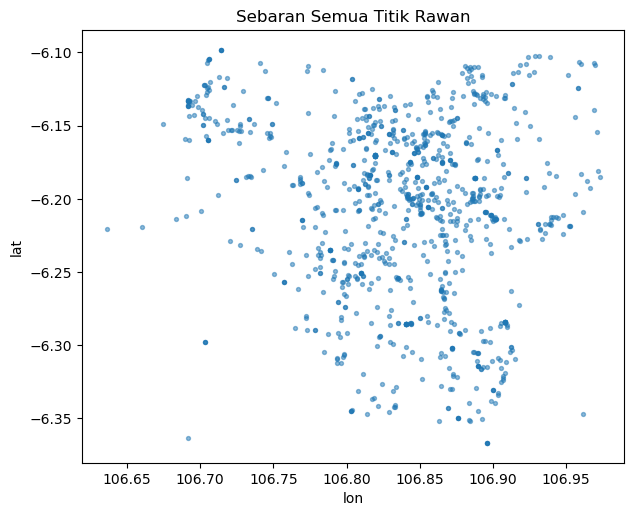

In [133]:
plt.figure(figsize=(7, 7))
plt.scatter(df_baru["lon"], df_baru["lat"], s=8, alpha=0.5)
plt.gca().set_aspect("equal")
plt.title("Sebaran Semua Titik Rawan")
plt.xlabel("lon"); plt.ylabel("lat")
plt.show()

Scatter plot menunjukkan bahwa titik rawan tersebar di seluruh wilayah daratan DKI Jakarta, tetapi tidak merata. Titik paling rapat berada di bagian tengah, pada kisaran longitude 106.80-106.90 dan latitude -6.15 hingga -6.25. Dari area tersebut sebaran memanjang ke arah selatan, sementara bagian barat dan tepi utara terlihat jauh lebih jarang. Terdapat juga beberapa titik terpencil yang letaknya jauh dari kumpulan utama.

Pola ini menunjukkan bahwa titik rawan cenderung mengelompok pada area tertentu, sehingga data sesuai untuk dianalisis dengan metode clustering.

### 4.3 Jarak Antar Titik (Nearest Neighbor Distance)

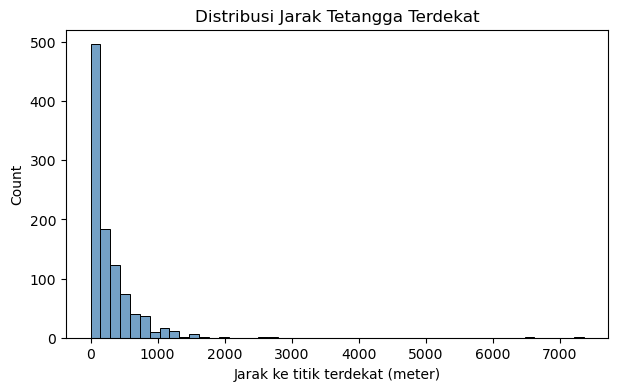

count   1007.000000
mean     276.300000
std      451.600000
min        0.200000
25%       14.500000
50%      151.900000
75%      383.200000
max     7353.700000
dtype: float64

In [134]:
from sklearn.neighbors import NearestNeighbors

X = np.radians(df_baru[["lat", "lon"]].values)
nn = NearestNeighbors(n_neighbors=2, metric="haversine").fit(X)
d, _ = nn.kneighbors(X)
jarak_m = d[:, 1] * 6371000          # meter

plt.figure(figsize=(7, 4))
sns.histplot(jarak_m, bins=50, color="steelblue")
plt.xlabel("Jarak ke titik terdekat (meter)")
plt.title("Distribusi Jarak Tetangga Terdekat")
plt.show()

pd.Series(jarak_m).describe().round(1)

Histogram jarak tetangga terdekat menunjukkan distribusi yang miring ke kanan. Median jarak ke titik terdekat adalah 151,9 meter dan 75% titik memiliki tetangga dalam radius 383,2 meter, sedangkan rata-ratanya (276,3 meter) lebih besar dari median karena adanya titik-titik terpencil, dengan jarak maksimum 7.353,7 meter.

Sekitar 25% titik berada dalam jarak kurang dari 14,5 meter dari titik lain (minimum 0,2 meter). Hal ini mengindikasikan adanya lokasi yang sama atau sangat berdekatan yang tercatat beberapa kali, misalnya untuk jenis gangguan berbeda.

### 4.4 Sebaran Spasial per Jenis Rawan

Gabung terlebih dahulu semua jenis pengamen menjadi satu

In [135]:
df_baru["jenis_gabung"] = df_baru["jenis_rawan"].replace({
    "PENGAMEN (COSTPLAY)": "PENGAMEN",
    "PENGAMEN (MANUSIA SILVER)": "PENGAMEN",
})
order = df_baru["jenis_gabung"].value_counts().index.tolist()

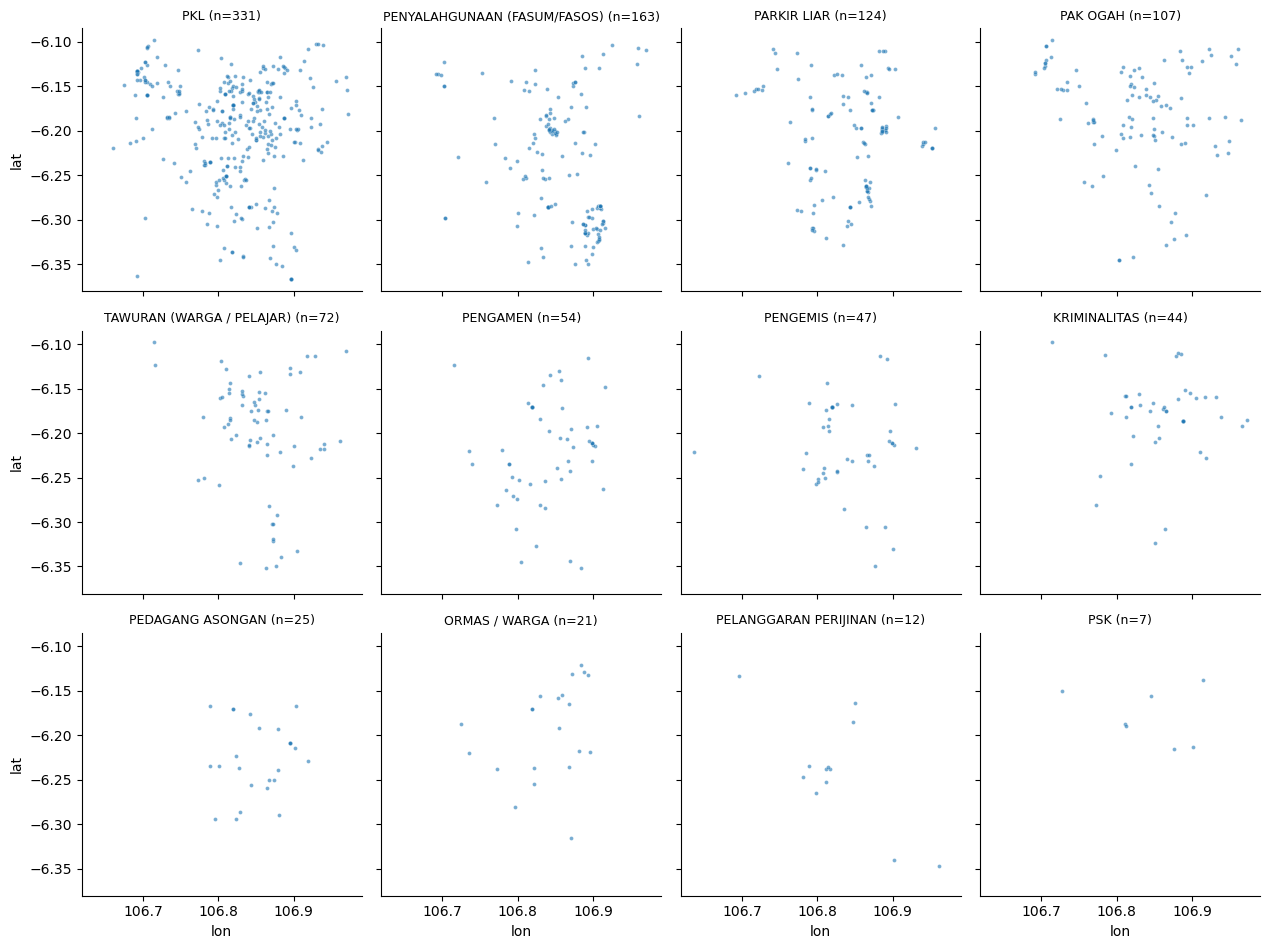

In [136]:
# facet scatter
g = sns.FacetGrid(df_baru, col="jenis_gabung", col_order=order,
                  col_wrap=4, height=3.2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, x="lon", y="lat", s=8, alpha=0.6)
for ax, j in zip(g.axes.flat, order):
    ax.set_title(f"{j} (n={(df_baru['jenis_gabung'] == j).sum()})", fontsize=9)
plt.show()

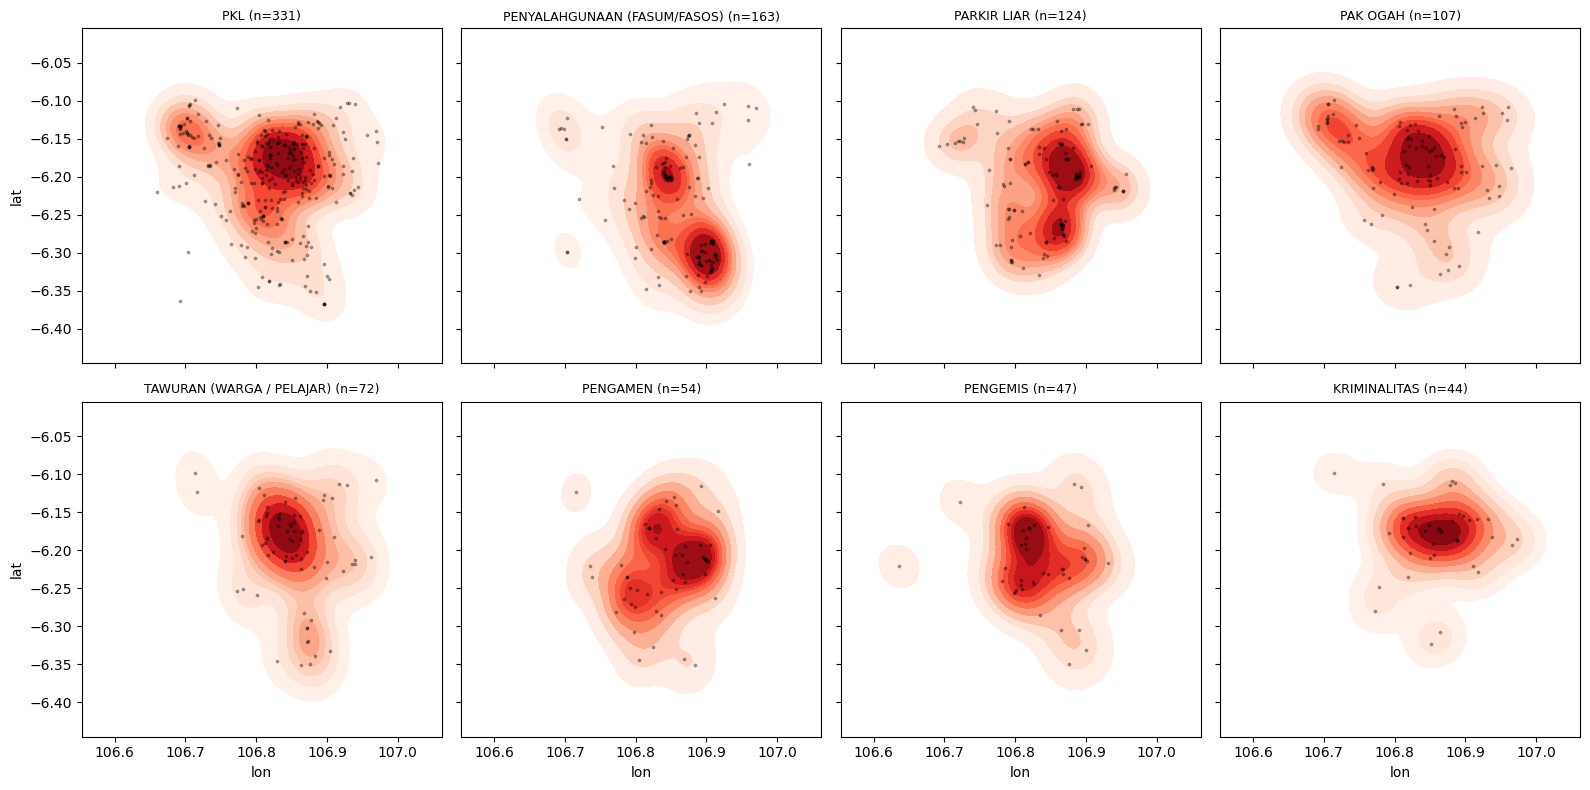

In [137]:
# facet KDE (hanya jenis dengan n >= 30)
big = [j for j in order if (df_baru["jenis_gabung"] == j).sum() >= 30]
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, j in zip(axes.flat, big):
    d_ = df_baru[df_baru["jenis_gabung"] == j]
    sns.kdeplot(data=d_, x="lon", y="lat", fill=True, cmap="Reds", thresh=0.05, ax=ax)
    ax.scatter(d_["lon"], d_["lat"], s=3, c="k", alpha=0.3)
    ax.set_title(f"{j} (n={len(d_)})", fontsize=9)
for ax in axes.flat[len(big):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Untuk membandingkan pola lokasi antar jenis, titik digambarkan terpisah untuk setiap jenis rawan (varian pengamen digabung menjadi satu kategori). Peta kepadatan (KDE) hanya dibuat untuk jenis dengan jumlah data minimal 30 titik, karena data yang terlalu sedikit menghasilkan kontur yang tidak dapat diandalkan. Jenis dengan data lebih sedikit (Pedagang Asongan, Ormas/Warga, Pelanggaran Perijinan, dan PSK) hanya ditampilkan sebagai scatter plot.

Hasilnya menunjukkan bahwa sebagian besar jenis rawan memiliki pusat kepadatan yang sama, yaitu di bagian tengah wilayah (sekitar latitude -6.17 hingga -6.20 dan longitude 106.83 hingga 106.87). Namun terdapat beberapa pola yang berbeda:

- **Penyalahgunaan Fasum/Fasos** memiliki dua pusat kepadatan: satu di bagian tengah dan satu yang lebih kuat di bagian tenggara (sekitar latitude -6.30, longitude 106.90).
- **Parkir Liar** tersebar lebih luas pada arah utara-selatan dengan beberapa titik puncak, ditambah kantong kecil di bagian barat.
- **Tawuran** berpusat di tengah dan memiliki kantong terpisah di bagian selatan (sekitar latitude -6.31, longitude 106.87).
- **Kriminalitas** paling terkonsentrasi di bagian tengah (sekitar latitude -6.17, longitude 106.87), dengan sedikit titik terpisah di selatan.
- **PKL dan Pak Ogah** mengikuti pola umum dengan tambahan kantong di bagian barat.

Perlu dicatat bahwa skala warna pada setiap panel KDE bersifat relatif terhadap jenisnya masing-masing, sehingga intensitas warna tidak dapat dibandingkan langsung antar jenis; yang dapat dibandingkan adalah bentuk dan lokasi pola kepadatannya.

Karena sebagian besar jenis berbagi pusat kepadatan yang sama, pembagian zona berdasarkan koordinat kemungkinan akan didominasi pemisahan antara area pusat dan area pinggiran. Perbedaan karakter antar jenis akan lebih jelas terlihat pada profil klaster yang dibuat setelah proses clustering.

## 5. Preprocessing data

### 5.1 Keputusan Preprocessing

Koreksi koordinat dan penanganan outlier sudah dilakukan pada bagian 4.1 (Persiapan Data Spasial), sehingga bagian ini berfokus pada perapian data lainnya:

1. Merapikan teks pada kolom kategorikal (menghapus spasi berlebih dan menyeragamkan huruf kapital).
2. Menggabungkan tiga varian jenis pengamen (Pengamen, Pengamen Manusia Silver, dan Pengamen Cosplay) menjadi satu kategori `PENGAMEN`. Kolom `jenis_rawan` asli tetap dipertahankan.
3. Membuang kolom yang tidak digunakan: `periode_data` (seluruh nilainya 2024) serta `latitude` dan `longitude` mentah yang sudah digantikan oleh `lat` dan `lon`.
4. Seluruh jenis rawan dipertahankan (tanpa filter), sehingga zona yang terbentuk menggambarkan kepadatan titik rawan ketertiban umum secara keseluruhan.
5. Titik dengan koordinat yang sangat berdekatan tidak digabung. Pengaruhnya diatasi pada tahap clustering melalui pemilihan `min_samples`.
6. Tidak dilakukan scaling, karena clustering hanya menggunakan `lat` dan `lon` yang berada pada satuan yang sama (K-Means) atau menggunakan jarak haversine (DBSCAN).

In [138]:
df_clean = df_baru.copy()

# 1. Rapikan teks
for c in ["wilayah", "kecamatan", "kelurahan", "jenis_rawan"]:
    df_clean[c] = df_clean[c].str.strip().str.upper()

# 2. Gabungkan varian PENGAMEN
df_clean["jenis_gabung"] = df_clean["jenis_rawan"].replace({
    "PENGAMEN (COSTPLAY)": "PENGAMEN",
    "PENGAMEN (MANUSIA SILVER)": "PENGAMEN",
})

# 3. Buang kolom yang tidak dipakai, susun ulang kolom
df_clean = df_clean[["wilayah", "kecamatan", "kelurahan",
                     "lat", "lon", "jenis_rawan", "jenis_gabung"]]
df_clean = df_clean.reset_index(drop=True)

# 4. Cek akhir
print("Ukuran data :", df_clean.shape)
print("Missing     :", df_clean.isna().sum().sum())
print("Duplikat    :", df_clean.duplicated().sum())
print()
print(df_clean["jenis_gabung"].value_counts())
df_clean.head()

Ukuran data : (1007, 7)
Missing     : 0
Duplikat    : 0

jenis_gabung
PKL                             331
PENYALAHGUNAAN (FASUM/FASOS)    163
PARKIR LIAR                     124
PAK OGAH                        107
TAWURAN (WARGA / PELAJAR)        72
PENGAMEN                         54
PENGEMIS                         47
KRIMINALITAS                     44
PEDAGANG ASONGAN                 25
ORMAS / WARGA                    21
PELANGGARAN PERIJINAN            12
PSK                               7
Name: count, dtype: int64


,wilayah,kecamatan,kelurahan,lat,lon,jenis_rawan,jenis_gabung
0,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6.170529,106.819195,PENGEMIS,PENGEMIS
1,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6.170492,106.819266,PKL,PKL
2,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6.160866,106.802437,TAWURAN (WARGA / PELAJAR),TAWURAN (WARGA / PELAJAR)
3,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6.159615,106.804436,TAWURAN (WARGA / PELAJAR),TAWURAN (WARGA / PELAJAR)
4,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI UTARA,-6.155287,106.801734,PKL,PKL


Setelah preprocessing, data bersih terdiri dari 1.007 baris dan 7 kolom tanpa missing value maupun duplikat. Jumlah data berkurang 11 baris dari data awal (1.018 baris), yaitu 9 titik Kepulauan Seribu yang dipisahkan karena terletak jauh dari daratan, dan 2 titik dengan koordinat salah ketik yang dibuang. Data bersih disimpan sebagai `data_bersih.csv` dan digunakan pada tahap clustering.

In [139]:
from pathlib import Path

out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)      # aman kalau folder sudah ada

df_clean.to_csv(out_dir / "data_bersih.csv", index=False)
print("Tersimpan di:", (out_dir / "data_bersih.csv").resolve())

Tersimpan di: C:\Users\Gerald\OneDrive\Documents\CAWU 4\github project\JagaDia\ML\data\processed\data_bersih.csv


Scaling tidak dilakukan karena kedua fitur berada pada satuan yang sama (derajat) dengan standar deviasi yang setara (0,061), btw ini sama AInya disuruh pake DBSCAN (digunakan untuk clustering, dimana mengelompokkan titik berdasarkan kepadatan: area yang titiknya rapat dianggap satu klaster, dan titik yang menyendiri dianggap noise. Cara kerjanya mirip melihat peta malam hari dari atas. Kumpulan lampu yang menyala rapat membentuk “kota” (klaster), sedangkan lampu yang berdiri sendirian di tengah sawah dianggap pencilan.)